# BDG2: análise exploratória

O Building Data Genome Project 2 (Miller et al., 2020) reúne medidores horários de energia de
1.636 edificações não residenciais em 19 sites, de 2016 e 2017. Este notebook verifica três
coisas antes do treino federado:

1. quais medidores cada site tem (as modalidades disponíveis para cada cliente);
2. quais sites e edificações passam nos critérios de qualidade e viram clientes;
3. o quanto os clientes escolhidos diferem entre si em escala, perfil de uso e dependência do
   clima. Essas diferenças são o que torna os dados não-IID entre clientes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bdg2_fl import graficos as gr
from bdg2_fl.config import (RAW, MEDIDORES_OPCIONAIS, MIN_PREENCHIMENTO, MIN_MEDIANA_KWH,
                            N_SITES, MAX_EDIF_POR_SITE)
from bdg2_fl.dados import selecionar

gr.aplicar_estilo()
pd.set_option("display.precision", 2)

meta = pd.read_csv(RAW / "metadata.csv")
elec = pd.read_csv(RAW / "electricity_cleaned.csv", index_col=0, parse_dates=True)
clima = pd.read_csv(RAW / "weather.csv", parse_dates=["timestamp"])

print(f"{meta.site_id.nunique()} sites, {len(meta)} edificações, "
      f"{elec.shape[1]} medidores de eletricidade, {len(elec)} horas "
      f"({elec.index.min():%Y-%m-%d} a {elec.index.max():%Y-%m-%d})")

19 sites, 1636 edificações, 1578 medidores de eletricidade, 17544 horas (2016-01-01 a 2017-12-31)


## 1. Modalidades por site

Cada edificação tem só parte dos medidores. A eletricidade é quase universal e por isso é a
variável-alvo. Os outros quatro medidores (água gelada, vapor, água quente e gás) entram no modelo
como modalidades opcionais.

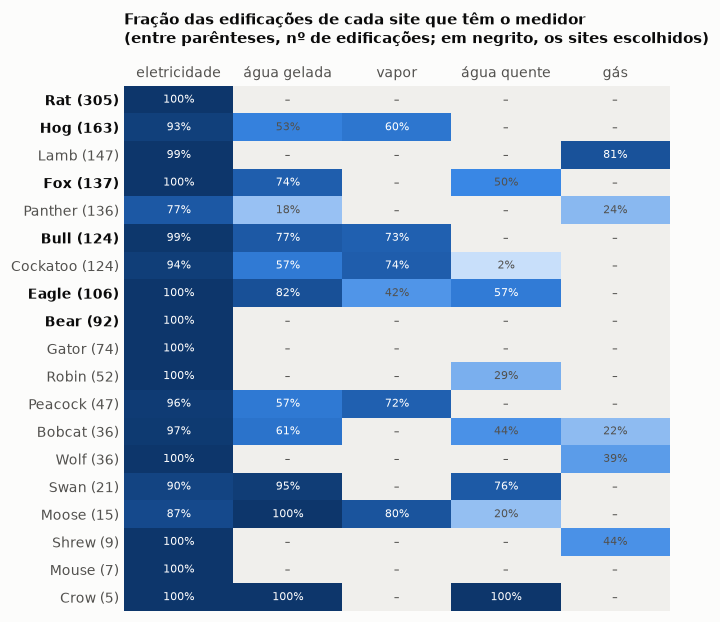

In [2]:
NOMES = {"electricity": "eletricidade", "chilledwater": "água gelada", "steam": "vapor",
         "hotwater": "água quente", "gas": "gás"}
medidores = ["electricity"] + MEDIDORES_OPCIONAIS

escolha = selecionar(elec)
sites = list(escolha)
cores = gr.cores_sites(sites)

n_edif = meta.groupby("site_id").size().sort_values(ascending=False)
cob = meta.groupby("site_id")[medidores].agg(lambda c: c.notna().mean()).loc[n_edif.index]

fig, ax = plt.subplots(figsize=(6.4, 6.2))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("azul", gr.SEQ_AZUL)
cmap.set_bad("#f0efec")
ax.imshow(np.ma.masked_equal(cob.values, 0), cmap=cmap, vmin=0, vmax=1, aspect="auto")
for i in range(cob.shape[0]):
    for j in range(cob.shape[1]):
        v = cob.values[i, j]
        ax.text(j, i, f"{v:.0%}" if v > 0 else "–", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if v > 0.55 else gr.TINTA_2)
ax.set_xticks(range(len(medidores)), [NOMES[m] for m in medidores])
ax.xaxis.tick_top()
rotulos = [f"{s} ({n})" for s, n in n_edif.items()]
ax.set_yticks(range(len(rotulos)), rotulos)
for t, s in zip(ax.get_yticklabels(), n_edif.index):
    if s in sites:
        t.set_fontweight("bold"); t.set_color(gr.TINTA)
ax.grid(False)
ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title("Fração das edificações de cada site que têm o medidor\n"
             "(entre parênteses, nº de edificações; em negrito, os sites escolhidos)", pad=28)
plt.show()

A eletricidade cobre quase todo o BDG2. Os outros medidores variam muito de site para site:
Rat e Bear só têm eletricidade, enquanto Eagle tem água gelada, vapor e água quente em boa parte das
edificações. Num cenário federado, os clientes não enxergam as mesmas grandezas.

## 2. Seleção dos clientes

Uma edificação entra se o medidor de eletricidade tiver:

- pelo menos 90% das horas com leitura, em 2016 e em 2017;
- mediana horária de pelo menos 1 kWh em cada ano;
- razão entre as medianas de 2017 e de 2016 entre 0,5 e 2.

O último critério exclui medidores que mudam de patamar entre os anos. A normalização usa as
estatísticas de 2016, e não valeria para 2017 nesses medidores. Os 6 sites com mais edificações
aprovadas viram clientes, cada um com no máximo 20 edificações.

In [3]:
e16, e17 = elec.loc["2016"], elec.loc["2017"]
preenchido = (e16.notna().mean() >= MIN_PREENCHIMENTO) & (e17.notna().mean() >= MIN_PREENCHIMENTO)
med16, med17 = e16.median(), e17.median()
estavel = (med16 >= MIN_MEDIANA_KWH) & (med17 >= MIN_MEDIANA_KWH) & (med17 / med16).between(0.5, 2.0)
site_de = pd.Series(elec.columns.str.split("_").str[0], index=elec.columns)

criterios = pd.DataFrame({
    "medidores": site_de.value_counts(),
    "preenchidos": site_de[preenchido].value_counts(),
    "aprovados": site_de[preenchido & estavel].value_counts(),
}).fillna(0).astype(int).sort_values("aprovados", ascending=False)
criterios["usadas"] = [min(a, MAX_EDIF_POR_SITE) if s in sites else 0
                       for s, a in criterios["aprovados"].items()]
criterios

,medidores,preenchidos,aprovados,usadas
Rat,305,259,247,20
Hog,152,136,134,20
Fox,137,130,126,20
Bull,123,109,109,20
Eagle,106,89,88,20
Bear,92,78,73,20
Robin,52,51,47,0
Wolf,36,36,36,0
Peacock,45,36,35,0
Gator,74,36,33,0


Sete sites (Panther, Cockatoo, Bobcat, Swan, Shrew, Mouse e Crow) não têm nenhuma edificação
com 90% das horas lidas nos dois anos. Lamb perde a maior parte no critério de estabilidade: 83
medidores preenchidos, só 27 aprovados. Os seis sites escolhidos têm entre 73 e 247 edificações
aprovadas, então é o limite de 20 por site que define o tamanho dos clientes, e todos ficam com o
mesmo número de edificações.

## 3. Escala das edificações

O modelo trabalha em z-score por edificação, então a escala não atrapalha o treino em si. Mas o
erro final é medido em kWh, e uma edificação muito maior que as outras domina o RMSE do seu site.

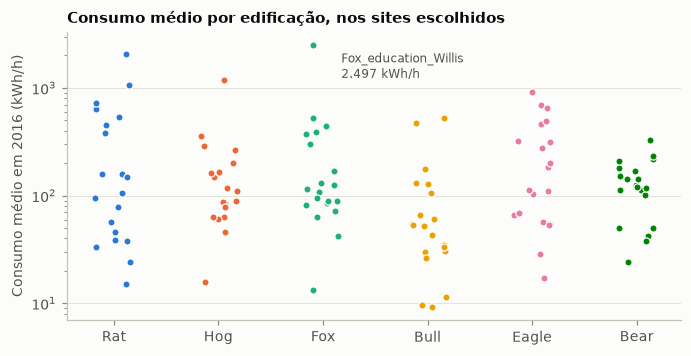

,mínimo,mediana,máximo
Rat,15.09,128.31,2048.10
Hog,15.86,99.88,1183.30
Fox,13.25,111.52,2496.68
Bull,9.26,52.84,526.83
Eagle,17.05,148.33,908.14
Bear,24.16,122.47,327.84


In [4]:
medias = {s: e16[escolha[s]].mean() for s in sites}

fig, ax = plt.subplots(figsize=(7.2, 3.4))
rng = np.random.default_rng(0)
for i, s in enumerate(sites):
    v = medias[s].values
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=22, color=cores[s],
               edgecolor=gr.SUPERFICIE, linewidth=0.8, zorder=3)
ax.set_yscale("log")
ax.set_xticks(range(len(sites)), sites)
ax.set_ylabel("Consumo médio em 2016 (kWh/h)")
ax.set_title("Consumo médio por edificação, nos sites escolhidos")
maior = max(((s, b, m) for s in sites for b, m in medias[s].items()), key=lambda t: t[2])
ax.annotate(f"{maior[1]}\n{maior[2]:,.0f} kWh/h".replace(",", "."),
            xy=(sites.index(maior[0]), maior[2]), xytext=(12, -4), textcoords="offset points",
            fontsize=8, color=gr.TINTA_2, va="top")
plt.show()

pd.DataFrame({s: medias[s].describe()[["min", "50%", "max"]] for s in sites}).T.rename(
    columns={"min": "mínimo", "50%": "mediana", "max": "máximo"})

Dentro de um mesmo site, o consumo médio das edificações varia em duas ordens de grandeza, de
~10 a ~2.500 kWh/h. As maiores estão em Fox (`Fox_education_Willis`, ~2.500 kWh/h) e em Rat (~2.050
kWh/h). Como o RMSE é calculado em kWh, o erro nessas poucas edificações grandes pesa mais no RMSE
do site do que o erro em todas as pequenas.

## 4. Um problema de qualidade que passou pela seleção

Dividindo cada edificação pela própria média de 2016, o maior valor relativo de cada site fica
abaixo de 4, com uma exceção.

In [5]:
rel = {s: e16[escolha[s]] / e16[escolha[s]].mean() for s in sites}
pd.DataFrame({s: {"edificação com maior pico": rel[s].max().idxmax(),
                  "pico / média": rel[s].max().max()} for s in sites}).T

,edificação com maior pico,pico / média
Rat,Rat_education_Elisa,3.8
Hog,Hog_assembly_Colette,3.57
Fox,Fox_assembly_Audrey,2.85
Bull,Bull_office_Efren,39.61
Eagle,Eagle_office_Donovan,3.28
Bear,Bear_education_Leonel,3.08


In [6]:
efren = e16["Bull_office_Efren"]
picos = efren[efren > 10 * efren.mean()]
print(f"Bull_office_Efren: média {efren.mean():.0f} kWh/h, {len(picos)} leituras acima de 10x a média")
print(picos.groupby(picos.index.hour).size().rename_axis("hora").rename("leituras").to_string())

horas_lidas = e16[escolha["Bull"]].notna().any(axis=1).resample("D").sum()
print(f"\nDias de 2016 em que o site Bull teve menos de 20 horas com alguma leitura: "
      f"{(horas_lidas < 20).sum()}")

Bull_office_Efren: média 53 kWh/h, 11 leituras acima de 10x a média
hora
1    9
7    1
8    1

Dias de 2016 em que o site Bull teve menos de 20 horas com alguma leitura: 14


`Bull_office_Efren` tem leituras de 800 a 2.000 kWh, quase todas à 01:00, contra uma média de
~50 kWh/h. É o padrão de medidor que despeja de uma vez o consumo acumulado depois de uma falha de
comunicação. Isso coincide com 14 dias em que o site Bull inteiro ficou quase sem leitura, e a
única leitura que sobra nesses dias é esse valor acumulado. O dado está no arquivo *cleaned* do
BDG2 e passou pelos critérios de seleção, que olham preenchimento e mediana, não picos.

No modelo, os lags são recortados em ±10 desvios-padrão, mas o alvo não. Essas horas entram no
treino de Bull como alvos 15 a 40 desvios-padrão acima do normal. O pipeline foi mantido como está
para os resultados baterem com o protótipo. Tratar esses picos é uma melhoria pendente.

## 5. Perfil ao longo do dia

Nos gráficos desta seção e da próxima, cada edificação é dividida pela própria média de 2016, e o
site é representado pela mediana dessas séries relativas. Assim cada edificação pesa igual (como no
z-score do modelo) e o valor 1 corresponde ao consumo médio. Para não deixar os picos acima
distorcerem o desenho, o perfil horário usa a mediana entre os dias, e o gráfico de clima ignora
dias com menos de 20 horas lidas.

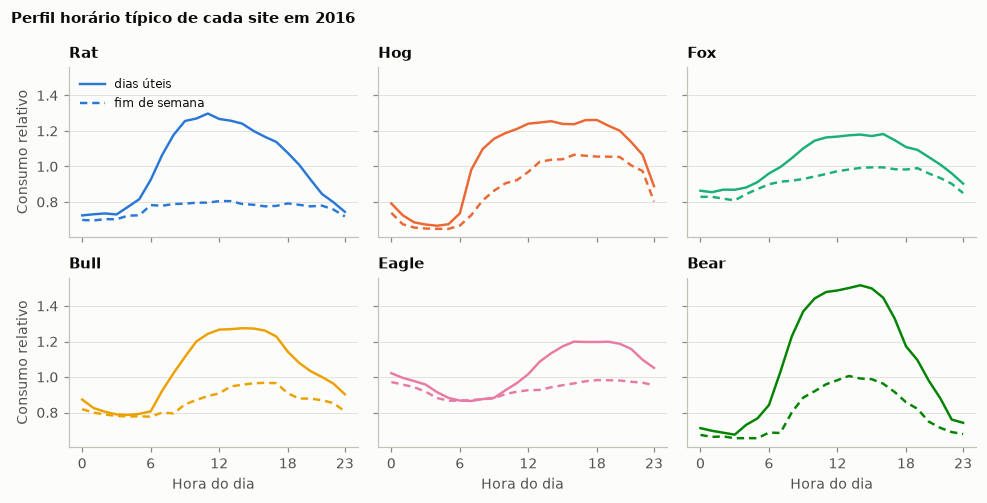

In [7]:
rel_site = {s: rel[s].median(axis=1) for s in sites}

fig, eixos = plt.subplots(2, 3, figsize=(9, 4.6), sharex=True, sharey=True)
for ax, s in zip(eixos.flat, sites):
    r = rel_site[s]
    util, fds = r[r.index.day_of_week < 5], r[r.index.day_of_week >= 5]
    util = util.groupby(util.index.hour).median()
    fds = fds.groupby(fds.index.hour).median()
    ax.plot(util.index, util.values, color=cores[s], label="dias úteis")
    ax.plot(fds.index, fds.values, color=cores[s], linestyle=(0, (3, 2)), label="fim de semana")
    ax.set_title(s)
    ax.set_xticks([0, 6, 12, 18, 23])
for ax in eixos[1]:
    ax.set_xlabel("Hora do dia")
for ax in eixos[:, 0]:
    ax.set_ylabel("Consumo relativo")
eixos[0, 0].legend(loc="upper left")
fig.suptitle("Perfil horário típico de cada site em 2016", x=0.01, ha="left",
             fontsize=10, fontweight="bold")
fig.tight_layout()
plt.show()

Os formatos diferem. Rat, Bear e Bull têm perfil de escritório: o consumo sobe a partir das 6h,
fica alto até o fim da tarde nos dias úteis, e o fim de semana fica bem abaixo. Bear tem o pico mais
pronunciado, perto de 1,5 vez a média às 14h. Hog sobe às 7h e só cai depois das 20h. Fox e Eagle
variam menos ao longo do dia, e em Eagle o mínimo é às 6h, não de madrugada.

## 6. Dependência do clima

Cada ponto é um dia de 2016: temperatura média do ar no site e consumo relativo do dia (mediana
entre as edificações).

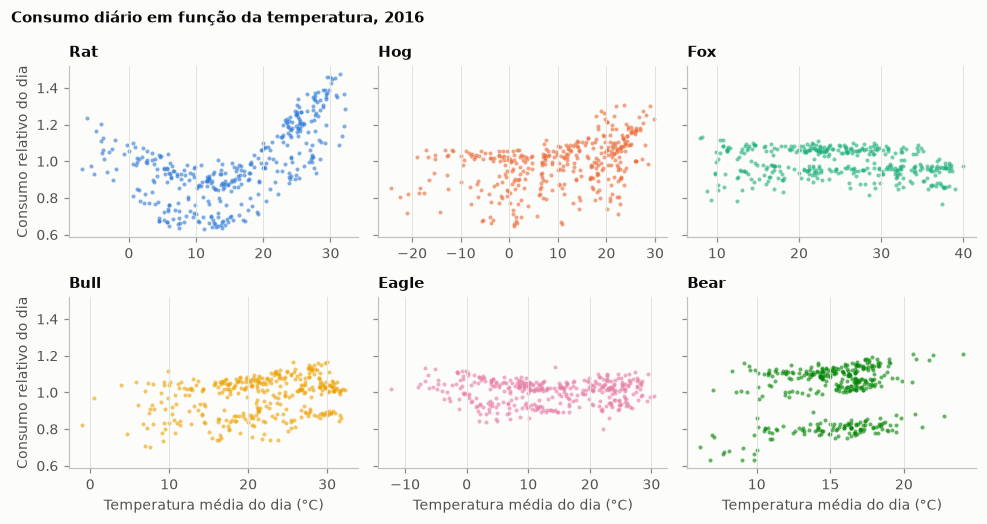

In [8]:
fig, eixos = plt.subplots(2, 3, figsize=(9, 4.8), sharey=True)
for ax, s in zip(eixos.flat, sites):
    lidas = rel_site[s].resample("D").count()
    dia = rel_site[s].resample("D").mean()[lidas >= 20]
    t = (clima[clima.site_id == s].set_index("timestamp")["airTemperature"]
         .loc["2016"].resample("D").mean())
    junto = pd.concat([t, dia], axis=1, keys=["t", "c"]).dropna()
    ax.scatter(junto.t, junto.c, s=7, color=cores[s], alpha=0.6, linewidth=0)
    ax.set_title(s)
    ax.grid(axis="both")
for ax in eixos[1]:
    ax.set_xlabel("Temperatura média do dia (°C)")
for ax in eixos[:, 0]:
    ax.set_ylabel("Consumo relativo do dia")
fig.suptitle("Consumo diário em função da temperatura, 2016", x=0.01, ha="left",
             fontsize=10, fontweight="bold")
fig.tight_layout()
plt.show()

A resposta à temperatura também muda de site para site:

- **Rat** tem forma de U: o consumo sobe no frio (aquecimento elétrico) e mais ainda no calor
  (resfriamento), com mínimo entre 10 e 15 °C.
- **Hog** sobe com o calor a partir de uns 10 °C e responde pouco ao frio, apesar de chegar a
  -20 °C. O aquecimento ali deve vir do vapor, que não é eletricidade.
- **Fox, Bull, Eagle e Bear** quase não respondem à temperatura. As duas faixas horizontais
  separadas que aparecem neles são dias úteis (acima) e fins de semana (abaixo).

## 7. Modalidades nas edificações escolhidas

Quantas das edificações escolhidas em cada site têm cada medidor opcional, segundo os metadados.
No modelo, um medidor só conta como presente se também tiver mais de 50% de leituras em 2016 e
variar de fato. Por isso, o número de medidores efetivamente usados pode ser um pouco menor.

In [9]:
m_idx = meta.set_index("building_id")
pd.DataFrame({
    s: {NOMES[m]: int(m_idx.loc[escolha[s], m].notna().sum()) for m in MEDIDORES_OPCIONAIS}
    | {"edificações": len(escolha[s])}
    for s in sites
}).T

,água gelada,vapor,água quente,gás,edificações
Rat,0,0,0,0,20
Hog,8,11,0,0,20
Fox,16,0,11,0,20
Bull,11,11,0,0,20
Eagle,16,10,10,0,20
Bear,0,0,0,0,20


Gás não aparece em nenhum dos seis sites, e Rat e Bear não têm nenhum medidor opcional entre as
edificações escolhidas. Na prática, três modalidades opcionais estão em jogo (água gelada, vapor e
água quente), distribuídas de forma desigual entre os clientes.

## O que isso significa para o treino federado

Os seis clientes diferem ao mesmo tempo nas grandezas que medem, no formato do perfil de uso e na
resposta à temperatura. Em termos de aprendizado federado, os dados são não-IID entre clientes: a
relação entre as features e o consumo que vale para um site não vale para outro. Um modelo global
único, como o que o FedAvg produz, precisa encontrar um meio-termo entre essas relações. O notebook
`treinamento.ipynb` mede quanto isso custa.